target_csemCur = 5000252545
P0_true = 335363.5650097035 Pa
alpha_true = 64.85958289678 Pa/day
tf = 236.87424931723152 days
number of sampling instants = 238
x_max_zoom = 50


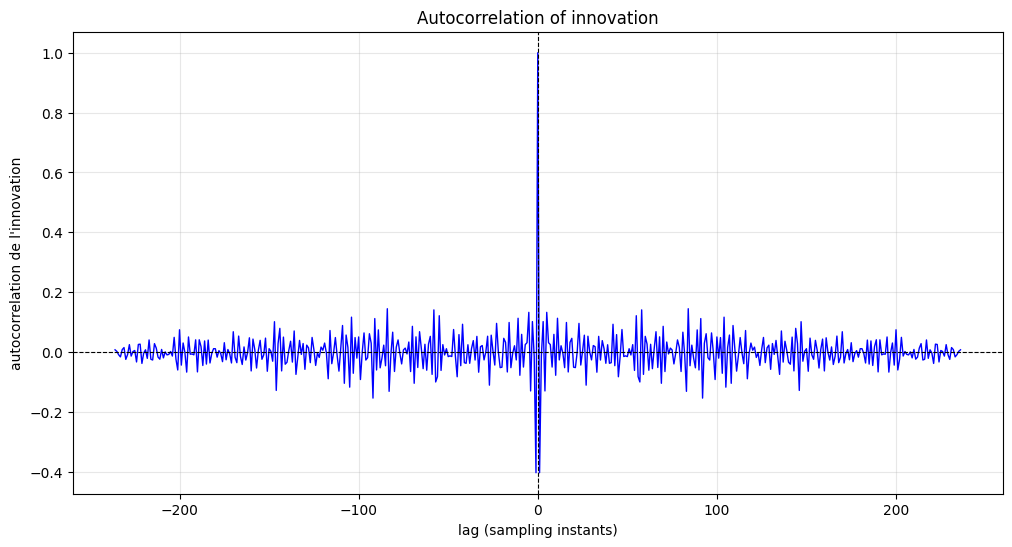

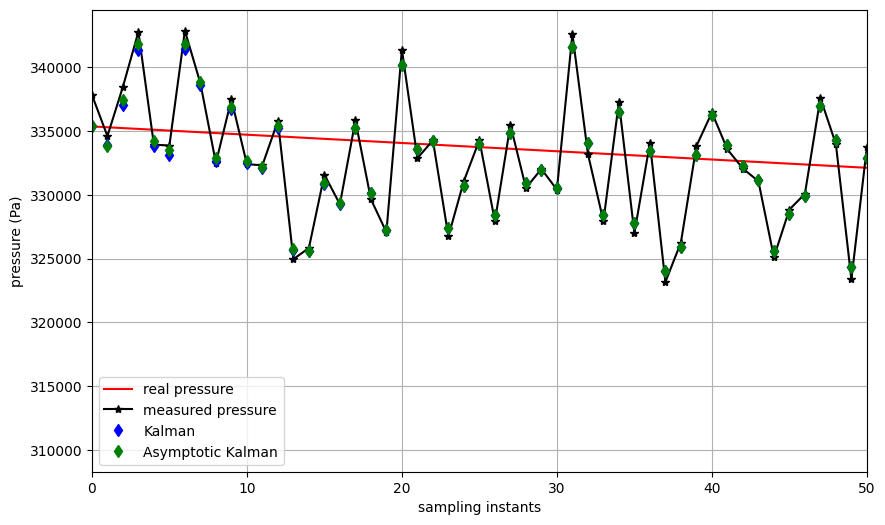

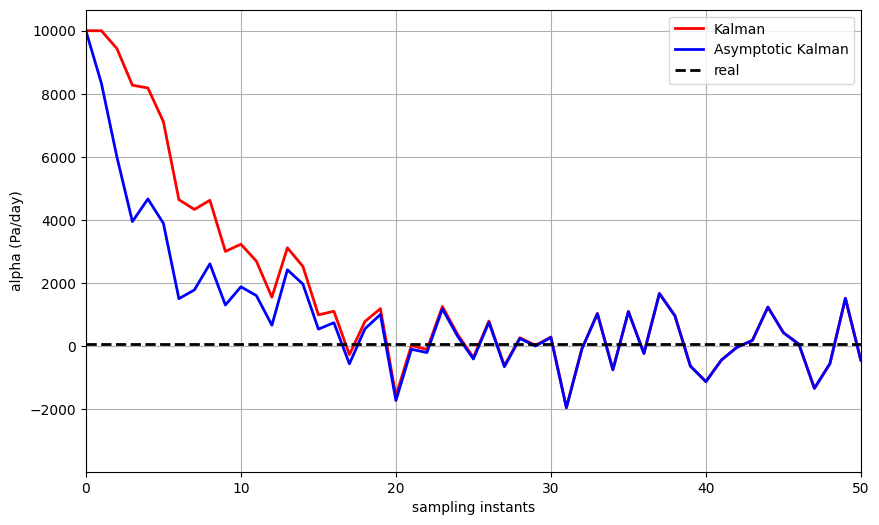

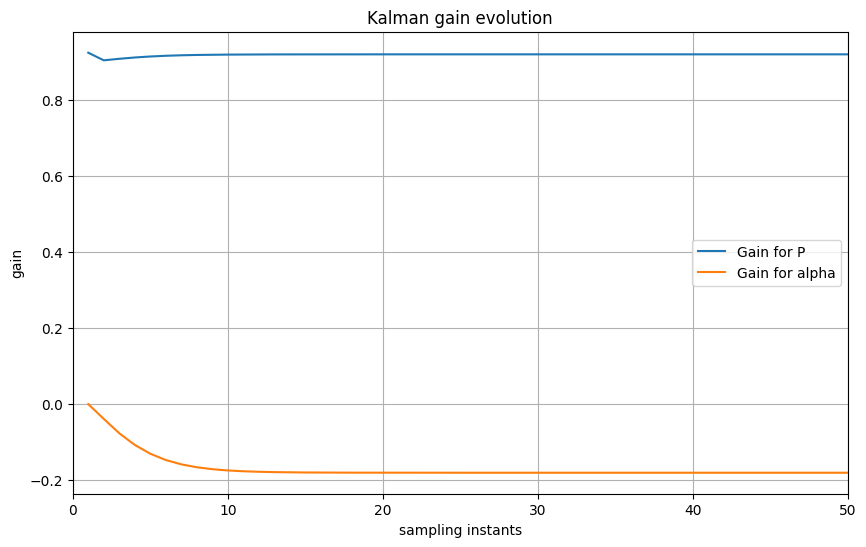

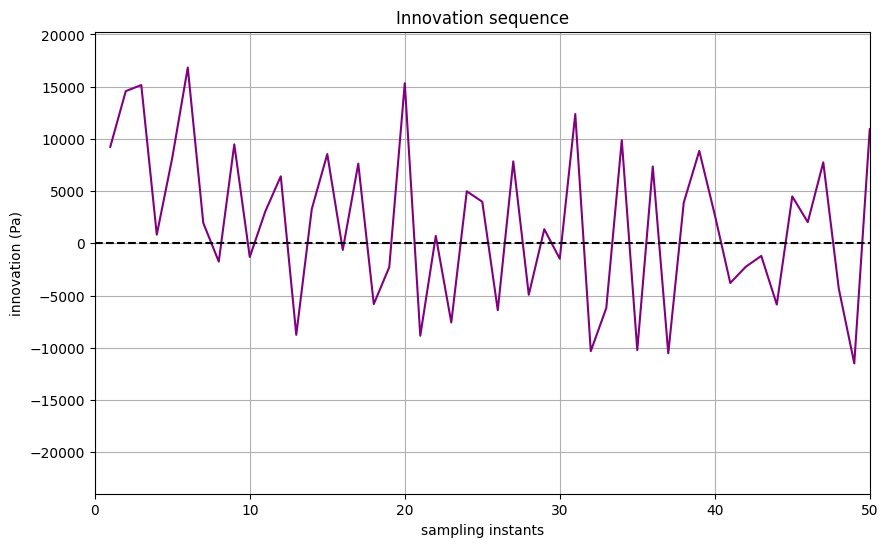

In [ ]:
# add autocorrelation figure
# x-axis changed to sampling instants instead of time (days)
# change pressure unit from bar to Pa
# alpha unit: Pa/day

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =========================
# 0. 基本设置
# =========================
plt.close('all')
np.random.seed(42)

# 压力单位转换：
# 1 bar = 100000 Pa
BAR_TO_PA = 1e5
BAR2_TO_PA2 = BAR_TO_PA ** 2


# =========================
# 1. 读取真实系统初始值
# =========================
df = pd.read_csv(
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv",
    encoding="utf-8-sig"
)


# target_csemCur = 5002343705
target_csemCur = 5000252545
# target_csemCur = 5000252447


df_csem = df[df['csemCur'] == target_csemCur].copy()


if df_csem.empty:
    raise ValueError(
        f"在 new_df_AlphaCorrected 中没有找到 csemCur = {target_csemCur} 的数据"
    )


row0 = df_csem.iloc[0]


# CSV 中的原始单位：
# compensatedRelativePressure_mafiltered: bar
# alpha: bar/day
P0_true_bar = float(row0['compensatedRelativePressure_mafiltered'])
alpha_true_bar_per_day = float(row0['alpha'])

# 转换为 Pa 和 Pa/day
P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


# =========================
# 2. 真实系统线性变化
# =========================
Te = 1  # sampling time (days)

# 目标终止压力：原来为 3.2 bar，现在转换为 Pa
P_final = 3.2 * BAR_TO_PA


if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前读取到的是 "
        f"{alpha_true} Pa/day"
    )


tf = (P0_true - P_final) / alpha_true


if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查 "
        f"P0_true={P0_true} Pa, "
        f"P_final={P_final} Pa, "
        f"alpha_true={alpha_true} Pa/day"
    )


temps = np.arange(0, tf + Te, Te)
sampling_instants = np.arange(len(temps))


# 真实压力，单位 Pa
P_true = P0_true - temps * alpha_true


# =========================
# 3. 测量噪声
# =========================
# 原始测量噪声：0.05 bar
sigma_meas_bar = 0.05

# 转换为 Pa
sigma_meas = sigma_meas_bar * BAR_TO_PA

# 测量压力，单位 Pa
P_measured = P_true + sigma_meas * np.random.randn(len(P_true))


# =========================
# 4. 压力图
# =========================
plt.figure(1, figsize=(10, 6))
plt.plot(
    sampling_instants,
    P_true,
    'r',
    label='real pressure'
)
plt.plot(
    sampling_instants,
    P_measured,
    '*-k',
    label='measured pressure'
)


# =========================
# 5. Kalman filtering
# =========================
# 原始 Q 中：
# 0.02 的单位对应压力状态 P 的方差，单位 bar^2
# 1e-3 的单位对应 alpha 状态的方差，单位 (bar/day)^2
#
# 转换到 Pa 后，方差需要乘以 (1e5)^2
Q_bar = Te * np.diag([0.02, 1e-3])
Q = Q_bar * BAR2_TO_PA2 



# R 是测量噪声方差，单位从 bar^2 转换为 Pa^2
R = sigma_meas ** 2


# 初始协方差：
# 第一个状态为压力 P
# 第二个状态为压力变化率 alpha
Sigma_priori_init_bar = np.diag([0.01, 1e-6])
Sigma_priori_init = Sigma_priori_init_bar * BAR2_TO_PA2


# alpha 初值：原来为 0.1 bar/day
alpha0_bar_per_day = 0.1
alpha0 = alpha0_bar_per_day * BAR_TO_PA


P0 = P0_true


x0 = np.array([
    [P0],
    [alpha0]
])


Kalman_states = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()

# 观测压力 P
H = np.array([[1, 0]])

Kalman_gain = np.empty((2, 0))


# 保存 innovation，单位 Pa
innovations = []


for k in range(len(temps) - 1):

    A = np.array([
        [1, -Te],
        [0,  1]
    ])


    x_priori = A @ x_posteriori

    Sigma_priori = (
        A @ Sigma_posteriori @ A.T + Q
    )


    K = (
        Sigma_priori
        @ H.T
        @ np.linalg.inv(
            np.array([[R]]) + H @ Sigma_priori @ H.T
        )
    )


    Sigma_posteriori = (
        np.eye(2) - K @ H
    ) @ Sigma_priori


    innovation = (
        np.array([[P_measured[k + 1]]])
        - H @ x_priori
    )

    innovations.append(float(innovation.item()))


    x_posteriori = x_priori + K @ innovation


    Kalman_states = np.hstack(
        (Kalman_states, x_posteriori)
    )

    Kalman_gain = np.hstack(
        (Kalman_gain, K)
    )


innovations = np.array(innovations)


P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]


plt.figure(1)
plt.plot(
    sampling_instants,
    P_Kalman,
    'bd',
    label='Kalman'
)3


# =========================
# 6. Asymptotic Kalman filter
# =========================
alpha0_2_bar_per_day = 0.1
alpha0_2 = alpha0_2_bar_per_day * BAR_TO_PA

P0_2 = P0_true


x0 = np.array([
    [P0_2],
    [alpha0_2]
])


Kalman_states2 = x0.copy()
x_priori = x0.copy()
Sigma_posteriori = Sigma_priori_init.copy()
x_posteriori = x0.copy()

H = np.array([[1, 0]])


K = Kalman_gain[:, -1].reshape(2, 1)


for k in range(len(temps) - 1):

    A = np.array([
        [1, -Te],
        [0,  1]
    ])


    x_priori = A @ x_posteriori

    Sigma_priori = (
        A @ Sigma_posteriori @ A.T + Q
    )


    Sigma_posteriori = (
        np.eye(2) - K @ H
    ) @ Sigma_priori


    innovation = (
        np.array([[P_measured[k + 1]]])
        - H @ x_priori
    )


    x_posteriori = x_priori + K @ innovation


    Kalman_states2 = np.hstack(
        (Kalman_states2, x_posteriori)
    )


P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]


plt.figure(1)
plt.plot(
    sampling_instants,
    P_Kalman2,
    'gd',
    label='Asymptotic Kalman'
)

plt.xlabel('sampling instants')
plt.ylabel('pressure (Pa)')
plt.grid(True)
plt.legend()


# =========================
# 7. alpha 图
# =========================
plt.figure(2, figsize=(10, 6))

plt.plot(
    sampling_instants,
    alpha_Kalman,
    'r',
    linewidth=2,
    label='Kalman'
)

plt.plot(
    sampling_instants,
    alpha_Kalman2,
    'b',
    linewidth=2,
    label='Asymptotic Kalman'
)

plt.plot(
    sampling_instants,
    alpha_true * np.ones_like(sampling_instants),
    'k--',
    linewidth=2,
    label='real'
)

plt.grid(True)
plt.xlabel('sampling instants')
plt.ylabel('alpha (Pa/day)')
plt.legend()


# =========================
# 8. Kalman gain 图
# =========================
sampling_instants_gain = np.arange(1, len(temps))


plt.figure(3, figsize=(10, 6))

plt.plot(
    sampling_instants_gain,
    Kalman_gain[0, :],
    label='Gain for P'
)

plt.plot(
    sampling_instants_gain,
    Kalman_gain[1, :],
    label='Gain for alpha'
)

plt.title('Kalman gain evolution')
plt.xlabel('sampling instants')
plt.ylabel('gain')
plt.grid(True)
plt.legend()


# =========================
# 9. Innovation 序列
# =========================
sampling_instants_innov = np.arange(1, len(temps))


plt.figure(4, figsize=(10, 6))

plt.plot(
    sampling_instants_innov,
    innovations,
    color='purple',
    linewidth=1.5
)

plt.axhline(
    0,
    color='black',
    linestyle='--'
)

plt.title('Innovation sequence')
plt.xlabel('sampling instants')
plt.ylabel('innovation (Pa)')
plt.grid(True)


# =========================
# 10. Innovation 对称自相关图
# =========================
x = np.asarray(innovations, dtype=float)
x = x - np.mean(x)


acf_full = np.correlate(
    x,
    x,
    mode='full'
)

acf_full = (
    acf_full / acf_full[len(x) - 1]
)


lags = np.arange(
    -(len(x) - 1),
    len(x)
)


max_lag = min(
    2000,
    len(x) - 1
)

mask = (
    (lags >= -max_lag)
    & (lags <= max_lag)
)


plt.figure(5, figsize=(12, 6))

plt.plot(
    lags[mask],
    acf_full[mask],
    color='blue',
    linewidth=1
)

plt.axhline(
    0,
    color='black',
    linestyle='--',
    linewidth=0.8
)

plt.axvline(
    0,
    color='black',
    linestyle='--',
    linewidth=0.8
)

plt.xlabel('lag (sampling instants)')
plt.ylabel("autocorrelation de l'innovation")
plt.title('Autocorrelation of innovation')
plt.grid(True, alpha=0.3)


# =========================
# 11. 放大 x 轴前段
# =========================
x_max_zoom = min(
    50,
    len(sampling_instants) - 1
)


plt.figure(1)
plt.xlim(0, x_max_zoom)

plt.figure(2)
plt.xlim(0, x_max_zoom)

plt.figure(3)
plt.xlim(0, x_max_zoom)

plt.figure(4)
plt.xlim(0, x_max_zoom)


# =========================
# 12. 打印关键信息
# =========================
print("target_csemCur =", target_csemCur)
print("P0_true =", P0_true, "Pa")
print("alpha_true =", alpha_true, "Pa/day")
print("tf =", tf, "days")
print("number of sampling instants =", len(sampling_instants))
print("x_max_zoom =", x_max_zoom)


plt.show()


========== Q tuning results ==========
 q_scale  pressure_rmse_Pa  pressure_mae_Pa  innovation_rmse_Pa
0.562000       2886.392453      2196.501515         6717.135812
0.630574       2887.185972      2209.397321         6710.814419
0.500883       2892.575324      2186.021994         6727.542468
0.707516       2894.301432      2223.509815         6708.399926
0.446412       2906.382032      2177.545140         6742.232387
0.793846       2907.090732      2238.815548         6709.733541
0.890710       2924.923999      2256.813609         6714.675679
0.397866       2928.438936      2170.963500         6761.423020
0.999393       2947.199560      2278.474887         6723.105238
0.354598       2959.337336      2167.562868         6785.350905

========== Selected parameters ==========
best_q_scale = 5.620000e-01
best_pressure_RMSE = 2886.392453 Pa

========== Noise parameters ==========
sigma_meas = 5000.000000 Pa
R = 2.500000e+07 Pa^2

Q_base =
[[1000000.       0.]
 [      0. 1000000.]]

Q_sel

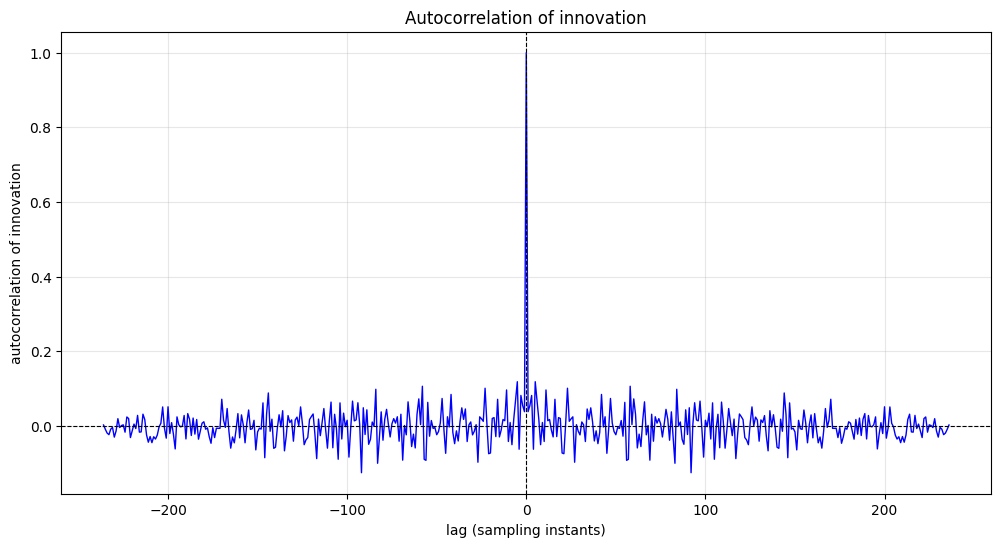

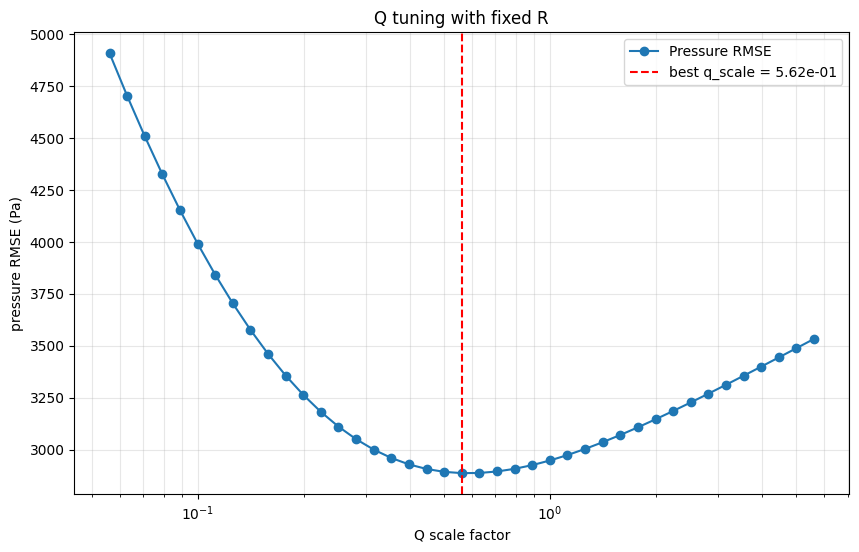

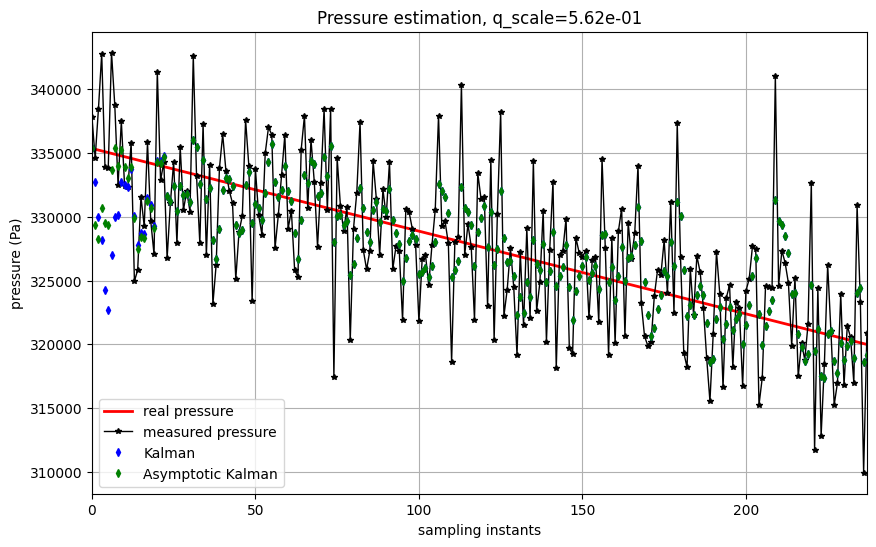

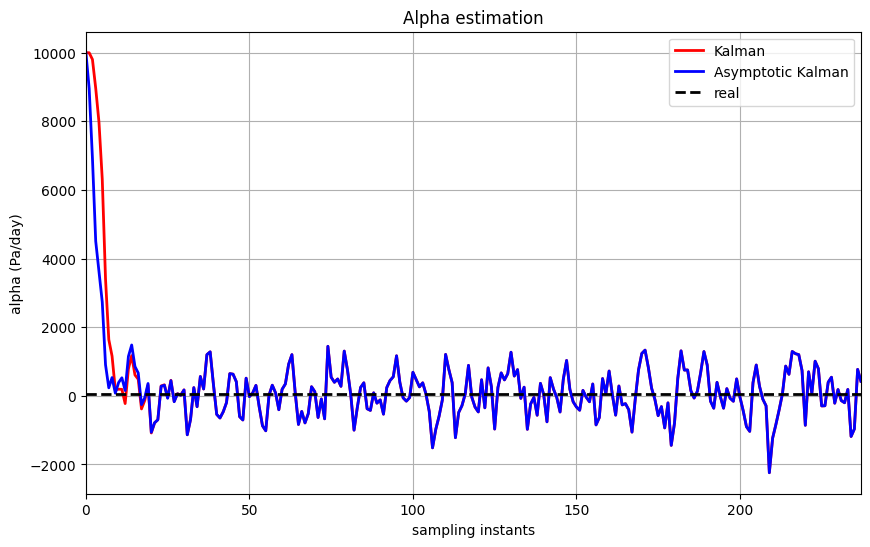

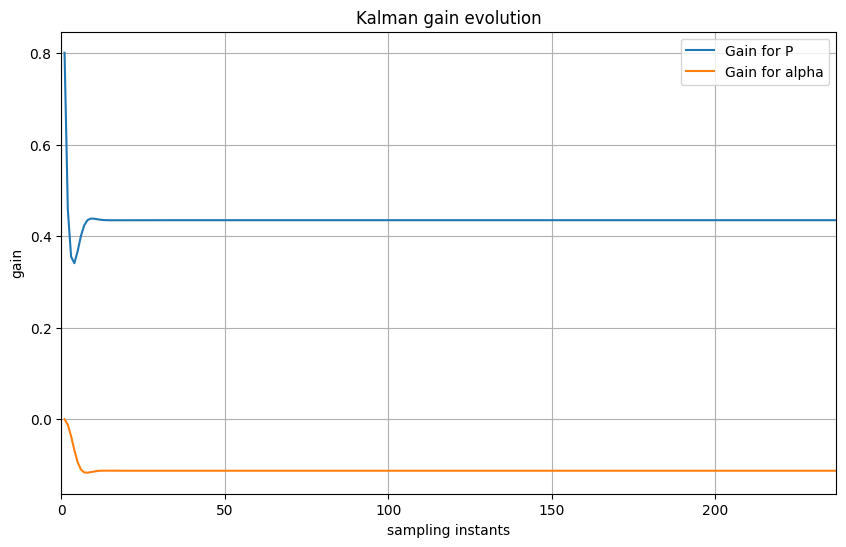

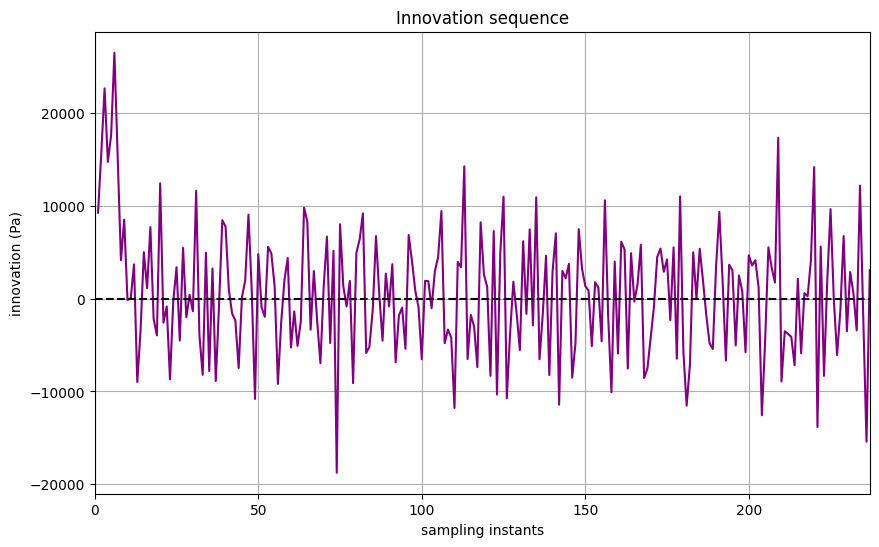

In [10]:
# ============================================================
# Kalman filtering with pressure unit conversion and Q tuning
#
# Pressure unit:
#     Pa
#
# Alpha unit:
#     Pa/day
#
# Original CSV units:
#     pressure: bar
#     alpha:    bar/day
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. 基本设置
# ============================================================
plt.close("all")
np.random.seed(42)

# 单位转换
BAR_TO_PA = 1e5
BAR2_TO_PA2 = BAR_TO_PA ** 2


# ============================================================
# 1. 读取真实系统初始值
# ============================================================
df = pd.read_csv(
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE/new_df_AlphaCorrected.csv",
    encoding="utf-8-sig"
)


# target_csemCur = 5002343705
target_csemCur = 5000252545
# target_csemCur = 5000252447


df_csem = df[df["csemCur"] == target_csemCur].copy()


if df_csem.empty:
    raise ValueError(
        f"在 new_df_AlphaCorrected 中没有找到 "
        f"csemCur = {target_csemCur} 的数据"
    )


row0 = df_csem.iloc[0]


# CSV 中的原始单位：
# compensatedRelativePressure_mafiltered: bar
# alpha: bar/day
P0_true_bar = float(
    row0["compensatedRelativePressure_mafiltered"]
)

alpha_true_bar_per_day = float(
    row0["alpha"]
)


# 转换为 Pa 和 Pa/day
P0_true = P0_true_bar * BAR_TO_PA
alpha_true = alpha_true_bar_per_day * BAR_TO_PA


# ============================================================
# 2. 真实系统线性变化
# ============================================================
Te = 1.0  # sampling time, day

# 原始终止压力为 3.2 bar
P_final_bar = 3.2

# 转换为 Pa
P_final = P_final_bar * BAR_TO_PA


if alpha_true <= 0:
    raise ValueError(
        f"alpha_true 必须大于 0，当前值为 "
        f"{alpha_true} Pa/day"
    )


# 计算终止时间
tf = (P0_true - P_final) / alpha_true


if tf <= 0:
    raise ValueError(
        f"计算得到 tf <= 0，请检查：\n"
        f"P0_true = {P0_true} Pa\n"
        f"P_final = {P_final} Pa\n"
        f"alpha_true = {alpha_true} Pa/day"
    )


temps = np.arange(
    0,
    tf + Te,
    Te
)

sampling_instants = np.arange(
    len(temps)
)


# 真实压力，单位 Pa
P_true = P0_true - temps * alpha_true


# ============================================================
# 3. 生成测量数据
# ============================================================
# 测量噪声标准差：
# 原始单位为 0.05 bar
sigma_meas_bar = 0.05

# 转换为 Pa
sigma_meas = sigma_meas_bar * BAR_TO_PA

# 测量压力，单位 Pa
P_measured = (
    P_true
    + sigma_meas * np.random.randn(len(P_true))
)


# ============================================================
# 4. 固定 R
# ============================================================
# R 是测量噪声协方差，单位 Pa^2
#
# sigma_meas = 0.05 bar = 5000 Pa
# R = (5000 Pa)^2 = 2.5e7 Pa^2
R = sigma_meas ** 2


# ============================================================
# 5. 设置初始协方差
# ============================================================
# 原始初始协方差：
# P:     0.01 bar^2
# alpha: 1e-6 (bar/day)^2
#
# 转换到 Pa 后，需要乘以 (1e5)^2
Sigma_priori_init_bar = np.diag([
    0.01,
    1e-6
])

Sigma_priori_init = (
    Sigma_priori_init_bar * BAR2_TO_PA2
)


# 初始 alpha：
# 原始单位为 0.1 bar/day
alpha0_bar_per_day = 0.1
alpha0 = alpha0_bar_per_day * BAR_TO_PA


# ============================================================
# 6. 设置 Q 的基准值
# ============================================================
# 这里不再直接把 0.02 作为最终 Q。
#
# 可以理解为：
# sigma_process_P_bar:
#     每个采样周期压力模型误差的标准差，单位 bar
#
# sigma_process_alpha_bar_per_day:
#     每个采样周期 alpha 模型误差的标准差，单位 bar/day
#
# 例如：
# sigma_process_P_bar = 0.01
# 表示压力模型误差标准差约为 0.01 bar
#
# 原来的 0.02 相当于：
# sqrt(0.02) = 0.1414 bar
# 这个过程噪声可能比较大。
sigma_process_P_bar = 0.01
sigma_process_alpha_bar_per_day = 0.01


# 由标准差计算方差
q_pressure_bar2 = sigma_process_P_bar ** 2

q_alpha_bar2_per_day2 = (
    sigma_process_alpha_bar_per_day ** 2
)


# 在 bar 单位下构造 Q
Q_base_bar = Te * np.diag([
    q_pressure_bar2,
    q_alpha_bar2_per_day2
])


# 转换为 Pa 相关单位
Q_base = Q_base_bar * BAR2_TO_PA2


# ============================================================
# 7. Kalman filter 函数
# ============================================================
def run_kalman_filter(
    P_measured,
    Te,
    Q,
    R,
    Sigma_priori_init,
    P0,
    alpha0
):
    """
    状态：
        x = [P, alpha]^T

    P:
        Pa

    alpha:
        Pa/day

    Q:
        过程噪声协方差

    R:
        测量噪声协方差，单位 Pa^2
    """

    n_samples = len(P_measured)

    # 状态转移矩阵
    A = np.array([
        [1.0, -Te],
        [0.0,  1.0]
    ])

    # 观测矩阵，只观测压力
    H = np.array([
        [1.0, 0.0]
    ])

    # 初始状态
    x0 = np.array([
        [P0],
        [alpha0]
    ], dtype=float)

    # 初始化
    x_posteriori = x0.copy()
    Sigma_posteriori = Sigma_priori_init.copy()

    Kalman_states = x0.copy()
    Kalman_gain = np.empty((2, 0))
    innovations = []

    # Kalman filtering
    for k in range(n_samples - 1):

        # -------------------------
        # Prediction
        # -------------------------
        x_priori = A @ x_posteriori

        Sigma_priori = (
            A
            @ Sigma_posteriori
            @ A.T
            + Q
        )

        # -------------------------
        # Kalman gain
        # -------------------------
        innovation_covariance = (
            np.array([[R]])
            + H @ Sigma_priori @ H.T
        )

        K = (
            Sigma_priori
            @ H.T
            @ np.linalg.inv(innovation_covariance)
        )

        # -------------------------
        # Innovation
        # -------------------------
        innovation = (
            np.array([[P_measured[k + 1]]])
            - H @ x_priori
        )

        innovations.append(
            float(innovation.item())
        )

        # -------------------------
        # Update state
        # -------------------------
        x_posteriori = (
            x_priori
            + K @ innovation
        )

        # -------------------------
        # Joseph form update
        # 数值稳定性通常优于：
        # (I - K @ H) @ Sigma_priori
        # -------------------------
        I = np.eye(2)

        Sigma_posteriori = (
            (I - K @ H)
            @ Sigma_priori
            @ (I - K @ H).T
            + K @ np.array([[R]]) @ K.T
        )

        # 保存结果
        Kalman_states = np.hstack([
            Kalman_states,
            x_posteriori
        ])

        Kalman_gain = np.hstack([
            Kalman_gain,
            K
        ])

    return (
        Kalman_states,
        Kalman_gain,
        np.asarray(innovations)
    )


# ============================================================
# 8. 搜索最佳 Q
# ============================================================
# q_scale 只改变 Q，不改变 R：
#
# Q_candidate = q_scale * Q_base
#
# q_scale 越小：
#     越相信模型
#
# q_scale 越大：
#     越相信测量值
# q_scale_grid = np.logspace(
#     -6,
#     2,
#     33
# )


q_scale_grid = np.logspace(
    np.log10(5.62e-1) - 1,
    np.log10(5.62e-1) + 1,
    41
)

q_search_results = []


for q_scale in q_scale_grid:

    Q_candidate = q_scale * Q_base

    (
        states_candidate,
        gain_candidate,
        innovations_candidate
    ) = run_kalman_filter(
        P_measured=P_measured,
        Te=Te,
        Q=Q_candidate,
        R=R,
        Sigma_priori_init=Sigma_priori_init,
        P0=P0_true,
        alpha0=alpha0
    )

    P_candidate = states_candidate[0, :]

    # 忽略开始阶段的初始化瞬态
    transient = min(
        5,
        max(0, len(P_true) // 10)
    )

    # 压力 RMSE
    pressure_rmse = np.sqrt(
        np.mean(
            (
                P_candidate[transient:]
                - P_true[transient:]
            ) ** 2
        )
    )

    # 压力 MAE
    pressure_mae = np.mean(
        np.abs(
            P_candidate[transient:]
            - P_true[transient:]
        )
    )

    # Innovation RMSE
    innovation_rmse = np.sqrt(
        np.mean(
            innovations_candidate ** 2
        )
    )

    q_search_results.append({
        "q_scale": q_scale,
        "pressure_rmse_Pa": pressure_rmse,
        "pressure_mae_Pa": pressure_mae,
        "innovation_rmse_Pa": innovation_rmse
    })


q_results_df = pd.DataFrame(
    q_search_results
)


# 按压力 RMSE 排序
q_results_sorted = q_results_df.sort_values(
    by="pressure_rmse_Pa",
    ascending=True
).reset_index(drop=True)


# 选择 RMSE 最小的 q_scale
best_q_scale = float(
    q_results_sorted.loc[0, "q_scale"]
)

best_pressure_rmse = float(
    q_results_sorted.loc[0, "pressure_rmse_Pa"]
)


# 最佳 Q
Q = best_q_scale * Q_base


# ============================================================
# 9. 输出 Q 搜索结果
# ============================================================
print("\n========== Q tuning results ==========")

print(
    q_results_sorted.head(10).to_string(
        index=False
    )
)

print("\n========== Selected parameters ==========")
print(f"best_q_scale = {best_q_scale:.6e}")
print(
    f"best_pressure_RMSE = "
    f"{best_pressure_rmse:.6f} Pa"
)

print("\n========== Noise parameters ==========")
print(f"sigma_meas = {sigma_meas:.6f} Pa")
print(f"R = {R:.6e} Pa^2")

print("\nQ_base =")
print(Q_base)

print("\nQ_selected =")
print(Q)


# ============================================================
# 10. 使用最佳 Q 运行正式 Kalman filter
# ============================================================
(
    Kalman_states,
    Kalman_gain,
    innovations
) = run_kalman_filter(
    P_measured=P_measured,
    Te=Te,
    Q=Q,
    R=R,
    Sigma_priori_init=Sigma_priori_init,
    P0=P0_true,
    alpha0=alpha0
)


P_Kalman = Kalman_states[0, :]
alpha_Kalman = Kalman_states[1, :]


# ============================================================
# 11. Asymptotic Kalman filter
# ============================================================
def run_asymptotic_kalman_filter(
    P_measured,
    Te,
    Q,
    R,
    Sigma_priori_init,
    P0,
    alpha0,
    K
):
    """
    使用固定 Kalman gain 的 asymptotic Kalman filter。
    """

    n_samples = len(P_measured)

    A = np.array([
        [1.0, -Te],
        [0.0,  1.0]
    ])

    H = np.array([
        [1.0, 0.0]
    ])

    x_posteriori = np.array([
        [P0],
        [alpha0]
    ], dtype=float)

    Sigma_posteriori = Sigma_priori_init.copy()

    Kalman_states = x_posteriori.copy()

    for k in range(n_samples - 1):

        # Prediction
        x_priori = A @ x_posteriori

        Sigma_priori = (
            A
            @ Sigma_posteriori
            @ A.T
            + Q
        )

        # 使用固定 gain
        Sigma_posteriori = (
            (np.eye(2) - K @ H)
            @ Sigma_priori
            @ (np.eye(2) - K @ H).T
            + K @ np.array([[R]]) @ K.T
        )

        innovation = (
            np.array([[P_measured[k + 1]]])
            - H @ x_priori
        )

        x_posteriori = (
            x_priori
            + K @ innovation
        )

        Kalman_states = np.hstack([
            Kalman_states,
            x_posteriori
        ])

    return Kalman_states


# 使用正式 Kalman filter 最后的 gain
K_asymptotic = Kalman_gain[:, -1].reshape(2, 1)


Kalman_states2 = run_asymptotic_kalman_filter(
    P_measured=P_measured,
    Te=Te,
    Q=Q,
    R=R,
    Sigma_priori_init=Sigma_priori_init,
    P0=P0_true,
    alpha0=alpha0,
    K=K_asymptotic
)


P_Kalman2 = Kalman_states2[0, :]
alpha_Kalman2 = Kalman_states2[1, :]


# ============================================================
# 12. 压力图
# ============================================================
plt.figure(1, figsize=(10, 6))

plt.plot(
    sampling_instants,
    P_true,
    "r",
    linewidth=2,
    label="real pressure"
)

plt.plot(
    sampling_instants,
    P_measured,
    "*-k",
    linewidth=1,
    markersize=4,
    label="measured pressure"
)

plt.plot(
    sampling_instants,
    P_Kalman,
    "bd",
    markersize=4,
    label="Kalman"
)

plt.plot(
    sampling_instants,
    P_Kalman2,
    "gd",
    markersize=4,
    label="Asymptotic Kalman"
)

plt.xlabel("sampling instants")
plt.ylabel("pressure (Pa)")
plt.title(
    f"Pressure estimation, q_scale={best_q_scale:.2e}"
)
plt.grid(True)
plt.legend()


# ============================================================
# 13. Alpha 图
# ============================================================
plt.figure(2, figsize=(10, 6))

plt.plot(
    sampling_instants,
    alpha_Kalman,
    "r",
    linewidth=2,
    label="Kalman"
)

plt.plot(
    sampling_instants,
    alpha_Kalman2,
    "b",
    linewidth=2,
    label="Asymptotic Kalman"
)

plt.plot(
    sampling_instants,
    alpha_true * np.ones_like(sampling_instants),
    "k--",
    linewidth=2,
    label="real"
)

plt.xlabel("sampling instants")
plt.ylabel("alpha (Pa/day)")
plt.title("Alpha estimation")
plt.grid(True)
plt.legend()


# ============================================================
# 14. Kalman gain 图
# ============================================================
sampling_instants_gain = np.arange(
    1,
    len(temps)
)


plt.figure(3, figsize=(10, 6))

plt.plot(
    sampling_instants_gain,
    Kalman_gain[0, :],
    label="Gain for P"
)

plt.plot(
    sampling_instants_gain,
    Kalman_gain[1, :],
    label="Gain for alpha"
)

plt.title("Kalman gain evolution")
plt.xlabel("sampling instants")
plt.ylabel("gain")
plt.grid(True)
plt.legend()


# ============================================================
# 15. Innovation 序列
# ============================================================
sampling_instants_innov = np.arange(
    1,
    len(temps)
)


plt.figure(4, figsize=(10, 6))

plt.plot(
    sampling_instants_innov,
    innovations,
    color="purple",
    linewidth=1.5
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.title("Innovation sequence")
plt.xlabel("sampling instants")
plt.ylabel("innovation (Pa)")
plt.grid(True)


# ============================================================
# 16. Innovation 对称自相关图
# ============================================================
x = np.asarray(
    innovations,
    dtype=float
)

x = x - np.mean(x)


if len(x) > 1 and np.var(x) > 0:

    acf_full = np.correlate(
        x,
        x,
        mode="full"
    )

    # 使用零滞后自相关进行归一化
    acf_full = (
        acf_full
        / acf_full[len(x) - 1]
    )

    lags = np.arange(
        -(len(x) - 1),
        len(x)
    )

    max_lag = min(
        2000,
        len(x) - 1
    )

    mask = (
        (lags >= -max_lag)
        & (lags <= max_lag)
    )

    plt.figure(5, figsize=(12, 6))

    plt.plot(
        lags[mask],
        acf_full[mask],
        color="blue",
        linewidth=1
    )

    plt.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8
    )

    plt.xlabel("lag (sampling instants)")
    plt.ylabel("autocorrelation of innovation")
    plt.title("Autocorrelation of innovation")
    plt.grid(True, alpha=0.3)


# ============================================================
# 17. Q 搜索结果
# ============================================================
plt.figure(6, figsize=(10, 6))

plt.semilogx(
    q_results_df["q_scale"],
    q_results_df["pressure_rmse_Pa"],
    "o-",
    linewidth=1.5,
    label="Pressure RMSE"
)

plt.axvline(
    best_q_scale,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=(
        f"best q_scale = "
        f"{best_q_scale:.2e}"
    )
)

plt.xlabel("Q scale factor")
plt.ylabel("pressure RMSE (Pa)")
plt.title("Q tuning with fixed R")
plt.grid(True, which="both", alpha=0.3)
plt.legend()


# ============================================================
# 18. 放大 x 轴前段
# ============================================================
x_max_zoom = min(
    2000,
    len(sampling_instants) - 1
)


plt.figure(1)
plt.xlim(0, x_max_zoom)

plt.figure(2)
plt.xlim(0, x_max_zoom)

plt.figure(3)
plt.xlim(0, x_max_zoom)

plt.figure(4)
plt.xlim(0, x_max_zoom)


# ============================================================
# 19. 打印关键信息
# ============================================================
print("\n========== System information ==========")
print("target_csemCur =", target_csemCur)
print(f"P0_true = {P0_true:.6f} Pa")
print(f"alpha_true = {alpha_true:.6f} Pa/day")
print(f"P_final = {P_final:.6f} Pa")
print(f"tf = {tf:.6f} days")
print(
    "number of sampling instants =",
    len(sampling_instants)
)
print("x_max_zoom =", x_max_zoom)


plt.show()

In [13]:
# ============================================================
# Diagnose q_scale_grid
# ============================================================

q_values = q_results_df["q_scale"].to_numpy()
rmse_values = q_results_df["pressure_rmse_Pa"].to_numpy()

best_index = np.argmin(rmse_values)
best_q_scale = q_values[best_index]

print("\n========== q_scale grid diagnosis ==========")
print("minimum q_scale =", q_values.min())
print("maximum q_scale =", q_values.max())
print("best q_scale    =", best_q_scale)
print("best index      =", best_index)
print("number of grid points =", len(q_values))

if best_index == 0:
    print(
        "WARNING: best q_scale is at the LOWER boundary."
    )
    print(
        "建议向更小的 q_scale 扩展搜索范围。"
    )

elif best_index == len(q_values) - 1:
    print(
        "WARNING: best q_scale is at the UPPER boundary."
    )
    print(
        "建议向更大的 q_scale 扩展搜索范围。"
    )

else:
    print(
        "best q_scale is inside the grid."
    )
    print(
        "当前搜索范围基本覆盖了最优区域。"
    )


========== q_scale grid diagnosis ==========
minimum q_scale = 0.0562
maximum q_scale = 5.62
best q_scale    = 0.5619999999999999
best index      = 20
number of grid points = 41
best q_scale is inside the grid.
当前搜索范围基本覆盖了最优区域。
